In [1]:
# import libraries for spatial data, tables, and plotting
import geopandas as gpd
import mapclassify
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [2]:
# import file path, legend, font, and raster tools
from pathlib import Path
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib import font_manager
import rasterio
from rasterio.mask import mask
from rasterio.warp import calculate_default_transform, reproject, Resampling
from rasterio.plot import plotting_extent


In [3]:
# locate the course folder from the repository or any nested notebook folder
working_dir = Path.cwd().resolve()
course_dir = next(
    (folder if folder.name == "_fall2026" else folder / "_fall2026"
     for folder in [working_dir, *working_dir.parents]
     if (folder.name == "_fall2026" and (folder / "data").is_dir())
     or (folder / "_fall2026" / "data").is_dir()),
    None
)
if course_dir is None:
    raise FileNotFoundError("Run this notebook inside the course repository.")

# use the current data location and preserve the original output PDFs
data_folder = course_dir / "data" / "assignement02-data"
assignment_folder = course_dir / "Assignments" / "Assignment 01 Data in and Design"
output_folder = assignment_folder / "Output"
output_folder.mkdir(parents=True, exist_ok=True)
boundaries_folder = data_folder / "limiti"
terrain_folder = data_folder / "orografia"

# register Roboto when available and embed TrueType text in PDF exports
font_files = list((course_dir / "Assignments").glob("*/data/fonts/Roboto-Light.ttf"))
if font_files:
    font_manager.fontManager.addfont(str(font_files[0]))
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(font_files[0])).get_name()
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["hatch.linewidth"] = 0.2


In [4]:
# inspect or prepare the next spatial analysis step
print("Boundary shapefiles:")
for file_path in sorted(boundaries_folder.rglob("*.shp")):
    print(file_path)

Boundary shapefiles:
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/data/assignement02-data/limiti/Com01012026/Com01012026_WGS84.shp
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/data/assignement02-data/limiti/ProvCM01012026/ProvCM01012026_WGS84.shp
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/data/assignement02-data/limiti/Reg01012026/Reg01012026_WGS84.shp
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/data/assignement02-data/limiti/RipGeo01012026/RipGeo01012026_WGS84.shp


In [5]:
# inspect or prepare the next spatial analysis step
print("\nTerrain shapefiles:")
for file_path in sorted(terrain_folder.rglob("*.shp")):
    print(file_path)


Terrain shapefiles:
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/data/assignement02-data/orografia/CTR_H_Orografia_1_L_parte1.shp
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/data/assignement02-data/orografia/CTR_H_Orografia_1_L_parte2.shp
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/data/assignement02-data/orografia/CTR_H_Orografia_1_S.shp


In [6]:
# load the municipality boundaries from the current data folder
boundaries_path = boundaries_folder / "Com01012026/Com01012026_WGS84.shp"
municipalities = gpd.read_file(boundaries_path)
municipalities.head()


Out[0]: 
   COD_RIP  ...                                           geometry
0        1  ...  POLYGON ((404703.561 5026682.656, 404733.562 5...
1        1  ...  POLYGON ((380700.909 4977305.52, 380702.627 49...
2        1  ...  POLYGON ((364710.856 5022090.677, 364725.872 5...
3        1  ...  POLYGON ((415942.51 5033304.612, 415962.885 50...
4        1  ...  POLYGON ((376934.55 4999073.855, 376941.551 49...

[5 rows x 13 columns]


In [7]:
# inspect or prepare the next spatial analysis step
print("Rows and columns:", municipalities.shape)
print("Coordinate reference system:", municipalities.crs)
print("Column names:", municipalities.columns.tolist())

Rows and columns: (7896, 13)
Coordinate reference system: EPSG:32632
Column names: ['COD_RIP', 'COD_REG', 'COD_PROV', 'COD_CM', 'COD_UTS', 'PRO_COM', 'PRO_COM_T', 'COMUNE', 'COMUNE_A', 'CC_UTS', 'Shape_Leng', 'Shape_Area', 'geometry']


In [8]:
# inspect or prepare the next spatial analysis step
pantelleria = municipalities[
    municipalities["COMUNE"].str.strip().str.casefold() == "pantelleria"
].copy()

print("Selected features:", len(pantelleria))

pantelleria.head()

Selected features: 1
Out[0]: 
      COD_RIP  ...                                           geometry
6531        5  ...  MULTIPOLYGON (((772569.225 4072227.947, 772555...

[1 rows x 13 columns]


In [9]:
# inspect or prepare the next spatial analysis step
fig, ax = plt.subplots(figsize=(8, 8))

pantelleria.plot(
    ax=ax,
    facecolor="#ffffff",
    edgecolor="#0000ff",
    linewidth=0.35,
)

ax.set_axis_off()

plt.show()

In [10]:
# inspect or prepare the next spatial analysis step
terrain_folder = data_folder / "orografia"
terrain_files = sorted(terrain_folder.rglob("*.shp"))

print("Available terrain shapefiles:")
for file_path in terrain_files:
    print(file_path)

Available terrain shapefiles:
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/data/assignement02-data/orografia/CTR_H_Orografia_1_L_parte1.shp
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/data/assignement02-data/orografia/CTR_H_Orografia_1_L_parte2.shp
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/data/assignement02-data/orografia/CTR_H_Orografia_1_S.shp


In [11]:
# inspect or prepare the next spatial analysis step
import pyogrio

for file_path in terrain_files:
    info = pyogrio.read_info(file_path)

    print("\nFile:", file_path.name)
    print("Coordinate system:", info["crs"])
    print("Geometry type:", info["geometry_type"])
    print("Fields:", info["fields"].tolist())


File: CTR_H_Orografia_1_L_parte1.shp
Coordinate system: EPSG:25833
Geometry type: LineString Z
Fields: ['OBJECTID', 'id', 'foglio', 'codice', 'descrizion', 'tipo', 'punti', 'ident', 'bordo', 'annorilev', 'flagstato', 'quota', 'st_length_', 'Shape_Leng']

File: CTR_H_Orografia_1_L_parte2.shp
Coordinate system: EPSG:25833
Geometry type: LineString Z
Fields: ['OBJECTID', 'id', 'foglio', 'codice', 'descrizion', 'tipo', 'punti', 'ident', 'bordo', 'annorilev', 'flagstato', 'quota', 'st_length_', 'Shape_Leng']

File: CTR_H_Orografia_1_S.shp
Coordinate system: EPSG:25833
Geometry type: Point Z
Fields: ['ID', 'FOGLIO', 'CODICE', 'DESCRIZION', 'TIPO', 'PROGRESSIV', 'PARZIALE', 'NUMCARATT', 'ANGOLOEST', 'ANGOLONORD', 'ALTEZ_SCAL', 'NUMERSPAZI', 'EST', 'NORD', 'QUOTA', 'TESTO', 'ANNORILEV', 'FLAGSTATO']


In [12]:
# inspect or prepare the next spatial analysis step
pantelleria = pantelleria.to_crs("EPSG:25833")

island_bounds = tuple(pantelleria.total_bounds)

print("Coordinate system:", pantelleria.crs)
print("Island bounds:", island_bounds)

Coordinate system: EPSG:25833
Island bounds: (np.float64(225759.69814973173), np.float64(4069526.423915387), np.float64(237325.53551278415), np.float64(4081389.0363300173))


In [13]:
# inspect or prepare the next spatial analysis step
terrain_folder = data_folder / "orografia"

line_files = sorted(terrain_folder.rglob("CTR_H_Orografia_1_L_parte*.shp"))

if len(line_files) != 2:
    raise ValueError(f"Expected two terrain line files, found {len(line_files)}.")

island_bounds = tuple(pantelleria.to_crs("EPSG:25833").total_bounds)

terrain_parts = [
    gpd.read_file(file_path, bbox=island_bounds) for file_path in line_files
]

terrain = gpd.GeoDataFrame(
    pd.concat(terrain_parts, ignore_index=True),
    geometry="geometry",
    crs="EPSG:25833",
)

print("Terrain features loaded:", len(terrain))

terrain[["codice", "descrizion"]].drop_duplicates()

Terrain features loaded: 748
Out[0]: 
  codice                   descrizion
0   H002   Curva di livello ordinaria
1   H006             Curva ausiliaria
9   H001  Curva di livello direttrice


In [14]:
# inspect or prepare the next spatial analysis step
codes = terrain["codice"].astype(str).str.strip().str.upper()

contours = terrain[codes.isin(["H001", "H002"])].copy()
contours["quota"] = pd.to_numeric(contours["quota"], errors="coerce")
contours = contours.dropna(subset=["quota"])

if contours.empty:
    raise ValueError(
        "No H001/H002 contours found. Check the codice and descrizion values."
    )

print("Contour features:", len(contours))
print("Lowest contour:", contours["quota"].min(), "m")
print("Highest contour:", contours["quota"].max(), "m")

Contour features: 632
Lowest contour: 10.0 m
Highest contour: 41035.0 m


In [15]:
# inspect or prepare the next spatial analysis step
contours = gpd.clip(contours, pantelleria, keep_geom_type=True)
contours = contours[contours.geometry.notna() & ~contours.geometry.is_empty].copy()

if contours.empty:
    raise ValueError("No contours overlap the island boundary.")

print("Contour features within Pantelleria:", len(contours))

Contour features within Pantelleria: 632


In [16]:
# inspect or prepare the next spatial analysis step
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

fig, ax = plt.subplots(figsize=(11, 11))

# Draw the island beneath the contours
pantelleria.plot(
    ax=ax,
    facecolor="#f5f2e9",
    edgecolor="none",
)

# Use the same elevation-to-colour scale for all contours
colour_map = plt.get_cmap("YlOrBr")
elevation_scale = Normalize(
    vmin=0,
    vmax=contours["quota"].max(),
)

# Emphasise major contours
major = contours["codice"].astype(str).str.strip().str.upper().eq("H001")

line_widths = major.map({True: 0.8, False: 0.3})

contours.plot(
    ax=ax,
    color=colour_map(elevation_scale(contours["quota"].to_numpy())),
    linewidth=line_widths.to_numpy(),
)

# Draw the boundary on top
pantelleria.boundary.plot(
    ax=ax,
    color="#383833",
    linewidth=0.8,
)

# Add an elevation legend
colour_bar = fig.colorbar(
    ScalarMappable(norm=elevation_scale, cmap=colour_map),
    ax=ax,
    shrink=0.55,
    pad=0.03,
)
colour_bar.set_label("Contour elevation (m)")

ax.set_title("Pantelleria — Island Topography", fontsize=18, pad=20)
ax.set_aspect("equal")
ax.set_axis_off()
ax.margins(0.06)

plt.show()

In [17]:
# inspect or prepare the next spatial analysis step
codes = terrain["codice"].astype(str).str.strip().str.upper()

contours = terrain[codes.isin(["H001", "H002"])].copy()

contours = gpd.clip(
    contours,
    pantelleria.to_crs(terrain.crs),
    keep_geom_type=True,
)

print("Contour lines:", len(contours))
# preserve numeric elevation values for subsequent mapping
contours["quota"] = pd.to_numeric(contours["quota"], errors="coerce")


Contour lines: 632


In [18]:
# inspect or prepare the next spatial analysis step
fig, ax = plt.subplots(figsize=(10, 10))

contours.plot(
    ax=ax,
    color="#FF6BFD",
    linewidth=0.30,
)

pantelleria.to_crs(contours.crs).boundary.plot(
    ax=ax,
    color="#FF6BFD",
    linewidth=0.45,
)

ax.set_aspect("equal")
ax.set_axis_off()

plt.show()

In [19]:
# inspect or prepare the next spatial analysis step
land_use_folder = data_folder / "uso_suolo"
land_use_files = sorted(land_use_folder.rglob("*.shp"))

print("Land-use shapefiles:")
for file_path in land_use_files:
    print(file_path)

Land-use shapefiles:
/Users/michelle/Desktop/GIT/cdp-mapping-systems/_fall2026/data/assignement02-data/uso_suolo/Carta_uso_suolo_Corine_Land_Cover_CLC.shp


In [20]:
# inspect or prepare the next spatial analysis step
import pyogrio

if not land_use_files:
    raise FileNotFoundError(f"No shapefiles found in {land_use_folder}")

for file_path in land_use_files:
    info = pyogrio.read_info(file_path)

    print("\nFile:", file_path.name)
    print("Coordinate system:", info["crs"])
    print("Geometry type:", info["geometry_type"])
    print("Fields:", info["fields"].tolist())


File: Carta_uso_suolo_Corine_Land_Cover_CLC.shp
Coordinate system: EPSG:7792
Geometry type: Polygon
Fields: ['OBJECTID', 'clc', 'nome_class']


In [21]:
# inspect or prepare the next spatial analysis step
land_use_parts = []

for file_path in land_use_files:
    info = pyogrio.read_info(file_path)

    # Read only polygon datasets
    if "polygon" not in info["geometry_type"].lower():
        continue

    # Match the island boundary to this dataset's coordinate system
    island_mask = pantelleria.to_crs(info["crs"])

    # Load features around Pantelleria
    part = gpd.read_file(
        file_path,
        bbox=tuple(island_mask.total_bounds),
    )

    if part.empty:
        continue

    # Trim features to the island boundary
    part = gpd.clip(part, island_mask, keep_geom_type=True)
    land_use_parts.append(part.to_crs(pantelleria.crs))

if not land_use_parts:
    raise ValueError("No land-use polygons found around Pantelleria.")

land_use = gpd.GeoDataFrame(
    pd.concat(land_use_parts, ignore_index=True),
    geometry="geometry",
    crs=pantelleria.crs,
)

print("Land-use features:", len(land_use))
print("Available fields:", land_use.columns.tolist())

land_use.head()

Land-use features: 986
Available fields: ['OBJECTID', 'clc', 'nome_class', 'geometry']
Out[0]: 
   OBJECTID  ...                                           geometry
0    333185  ...  POLYGON ((234573.894 4069747.548, 234568.588 4...
1    333214  ...  POLYGON ((234678.617 4070034.217, 234698.532 4...
2    333154  ...  POLYGON ((235497.792 4071052.543, 235475.165 4...
3    333180  ...  POLYGON ((234369.495 4070808.229, 234389.334 4...
4    333194  ...  POLYGON ((234395.933 4070640.192, 234297.004 4...

[5 rows x 4 columns]


In [22]:
# check the loaded land-use geometry types
print(land_use.geom_type.value_counts())
print("Coordinate system:", land_use.crs)


Polygon         980
MultiPolygon      6
Name: count, dtype: int64
Coordinate system: EPSG:25833


In [23]:
# inspect the original classification codes before grouping them
print(land_use["clc"].value_counts().sort_index())


clc
111        3
112      179
121        4
131        6
21121      5
221      151
223       16
242       75
31111     45
312        2
3121      42
321      188
3211      63
3222       7
3231     181
32312     11
332        4
3331       1
5122       1
521        2
Name: count, dtype: int64


In [24]:
# inspect or prepare the next spatial analysis step
fig, ax = plt.subplots(figsize=(10, 10))

# Draw land-use polygons
land_use.plot(
    ax=ax,
    facecolor="#e4e8d5",
    edgecolor="#8a927b",
    linewidth=0.3,
)

# Overlay contour lines
contours.to_crs(land_use.crs).plot(
    ax=ax,
    color="#806044",
    linewidth=0.25,
    alpha=0.7,
)

# Draw the island boundary
pantelleria.to_crs(land_use.crs).boundary.plot(
    ax=ax,
    color="#333333",
    linewidth=0.8,
)

ax.set_aspect("equal")
ax.set_axis_off()

plt.show()

In [25]:
# inspect or prepare the next spatial analysis step
print(land_use.drop(columns="geometry").head(10).to_string(index=False))

 OBJECTID  clc                                                                                   nome_class
   333185 3121 3121 Boschi a prevalenza di pini meditterranei (pino domestico, pino marittimo) e cipressete
   333214  321                                                       321 Aree a pascolo naturale e praterie
   333154 3231                                                                       3231 Macchia termofila
   333180 3121 3121 Boschi a prevalenza di pini meditterranei (pino domestico, pino marittimo) e cipressete
   333194  321                                                       321 Aree a pascolo naturale e praterie
   333192  321                                                       321 Aree a pascolo naturale e praterie
   333147 3121 3121 Boschi a prevalenza di pini meditterranei (pino domestico, pino marittimo) e cipressete
   333161  321                                                       321 Aree a pascolo naturale e praterie
   333128  242            24

In [26]:
# Standardise the original land-use codes
land_use["clc_code"] = (
    land_use["clc"].astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
)


def classify_land_use(code):
    if code == "221":
        return "Vineyards"
    if code.startswith("221"):
        return "Mixed vineyards"
    if code.startswith("2"):
        return "Other agricultural land"
    if code.startswith("3"):
        return "Forest and semi-natural land"
    if code.startswith("1"):
        return "Artificial surfaces"
    if code.startswith("4"):
        return "Wetlands"
    if code.startswith("5"):
        return "Water bodies"
    return "Unclassified"


land_use["map_category"] = land_use["clc_code"].apply(classify_land_use)

land_use[["clc_code", "map_category"]].drop_duplicates().sort_values("clc_code")

Out[0]: 
    clc_code                  map_category
296      111           Artificial surfaces
21       112           Artificial surfaces
601      121           Artificial surfaces
205      131           Artificial surfaces
371    21121       Other agricultural land
9        221                     Vineyards
200      223       Other agricultural land
8        242       Other agricultural land
91     31111  Forest and semi-natural land
832      312  Forest and semi-natural land
0       3121  Forest and semi-natural land
1        321  Forest and semi-natural land
11      3211  Forest and semi-natural land
197     3222  Forest and semi-natural land
2       3231  Forest and semi-natural land
100    32312  Forest and semi-natural land
179      332  Forest and semi-natural land
728     3331  Forest and semi-natural land
354     5122                  Water bodies
776      521                  Water bodies


In [27]:
# inspect or prepare the next spatial analysis step
from matplotlib.patches import Patch

palette = {
    "Vineyards": "#844580",
    "Mixed vineyards": "#bd8abb",
    "Other agricultural land": "#d9bd77",
    "Forest and semi-natural land": "#8fa88b",
    "Artificial surfaces": "#777777",
    "Wetlands": "#76b5ac",
    "Water bodies": "#96c6dc",
    "Unclassified": "#dddddd",
}

fig, ax = plt.subplots(figsize=(12, 10))

land_use.plot(
    ax=ax,
    color=land_use["map_category"].map(palette),
    edgecolor="none",
)

pantelleria.to_crs(land_use.crs).boundary.plot(
    ax=ax,
    color="#333333",
    linewidth=0.7,
)

legend_items = [
    Patch(facecolor=colour, label=category)
    for category, colour in palette.items()
    if category in land_use["map_category"].values
]

ax.legend(
    handles=legend_items,
    title="Land use",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False,
)

ax.set_title("Pantelleria — Cultivated Landscape", fontsize=18, pad=20)
ax.set_aspect("equal")
ax.set_axis_off()

plt.show()

In [28]:
# prepare matching layers for all three final maps
contours_map = contours.to_crs(land_use.crs)
island_map = pantelleria.to_crs(land_use.crs)
vineyards = land_use.loc[land_use["map_category"].eq("Vineyards")].copy()

# define a consistent frame for the island maps
xmin, ymin, xmax, ymax = island_map.total_bounds
map_width = xmax - xmin
map_height = ymax - ymin

# draw the common contour and coastline layers
def draw_relief(ax):
    contours_map.plot(ax=ax, color="#FF6BFD", linewidth=0.30, zorder=3)
    island_map.boundary.plot(ax=ax, color="#FF6BFD", linewidth=0.45, zorder=4)

# add the reference maps' north arrow and two-kilometer scale bar
def finish_map(ax, north_y=0.97):
    ax.set_xlim(xmin - map_width * 0.06, xmax + map_width * 0.06)
    ax.set_ylim(ymin - map_height * 0.10, ymax + map_height * 0.14)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.annotate("N", xy=(0.94, north_y), xytext=(0.94, north_y - 0.07),
                xycoords="axes fraction", ha="center", va="center", fontsize=7,
                arrowprops={"arrowstyle": "-|>", "linewidth": 0.5, "color": "black"})
    sx = xmin
    sy = ymin - map_height * 0.065
    ax.plot([sx, sx + 2000], [sy, sy], color="black", linewidth=0.5)
    for x in [sx, sx + 2000]:
        ax.plot([x, x], [sy - 45, sy + 45], color="black", linewidth=0.5)
    ax.text(sx + 1000, sy + 140, "2 km", ha="center", fontsize=7)

# export with the original filenames, preserving the exact 11-by-17-inch page size
def save_map(fig, original_name):
    destination = output_folder / original_name
    with plt.rc_context({"savefig.bbox": None}):
        fig.savefig(destination, format="pdf", dpi=300)
    print("Saved:", destination)

# define matching legend symbols for the vineyard maps
vineyard_legend = [
    Patch(facecolor="none", edgecolor="#00cfff", hatch=".....", linewidth=0.3, label="Vineyards"),
    Line2D([0], [0], color="#FF6BFD", linewidth=0.3, label="Contour lines")
]


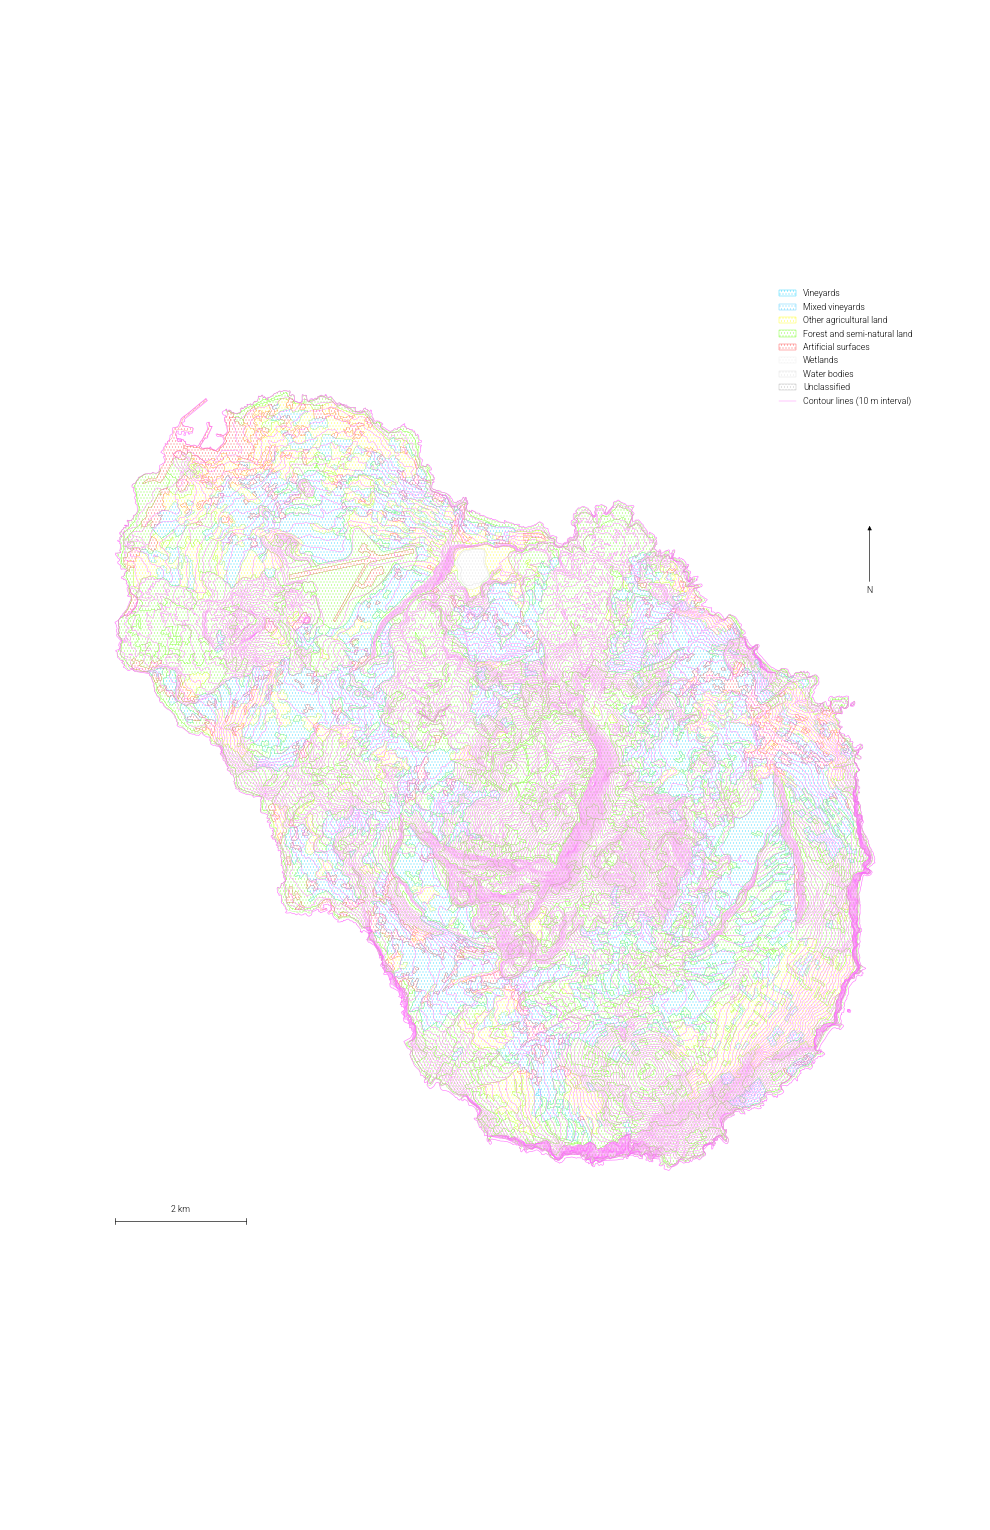

In [29]:
# draw the land-use map using the reference colors and dotted patterns
land_styles = {
    "Vineyards": "#00cfff",
    "Mixed vineyards": "#35c9ff",
    "Other agricultural land": "#ffff00",
    "Forest and semi-natural land": "#63ff00",
    "Artificial surfaces": "#ff3333",
    "Wetlands": "#eeeeee",
    "Water bodies": "#dddddd",
    "Unclassified": "#aaaaaa",
}
fig, ax = plt.subplots(figsize=(11, 17))
fig.subplots_adjust(left=0.07, right=0.93, bottom=0.10, top=0.90)
for category, color in land_styles.items():
    subset = land_use.loc[land_use["map_category"].eq(category)]
    if not subset.empty:
        subset.plot(ax=ax, facecolor="none", edgecolor=color,
                    hatch=".....", linewidth=0.15, zorder=1)
draw_relief(ax)
finish_map(ax, north_y=0.75)

# reproduce the full land-use legend, including contour lines
land_legend = [Patch(facecolor="none", edgecolor=color, hatch=".....",
                     linewidth=0.3, label=category)
               for category, color in land_styles.items()]
land_legend.append(Line2D([0], [0], color="#FF6BFD", linewidth=0.3,
                          label="Contour lines (10 m interval)"))
ax.legend(handles=land_legend, loc="upper right", fontsize=7, frameon=False,
          bbox_to_anchor=(1.0, 1.0))
save_map(fig, "Assignement01-Map01-Landuse.pdf")
plt.show()


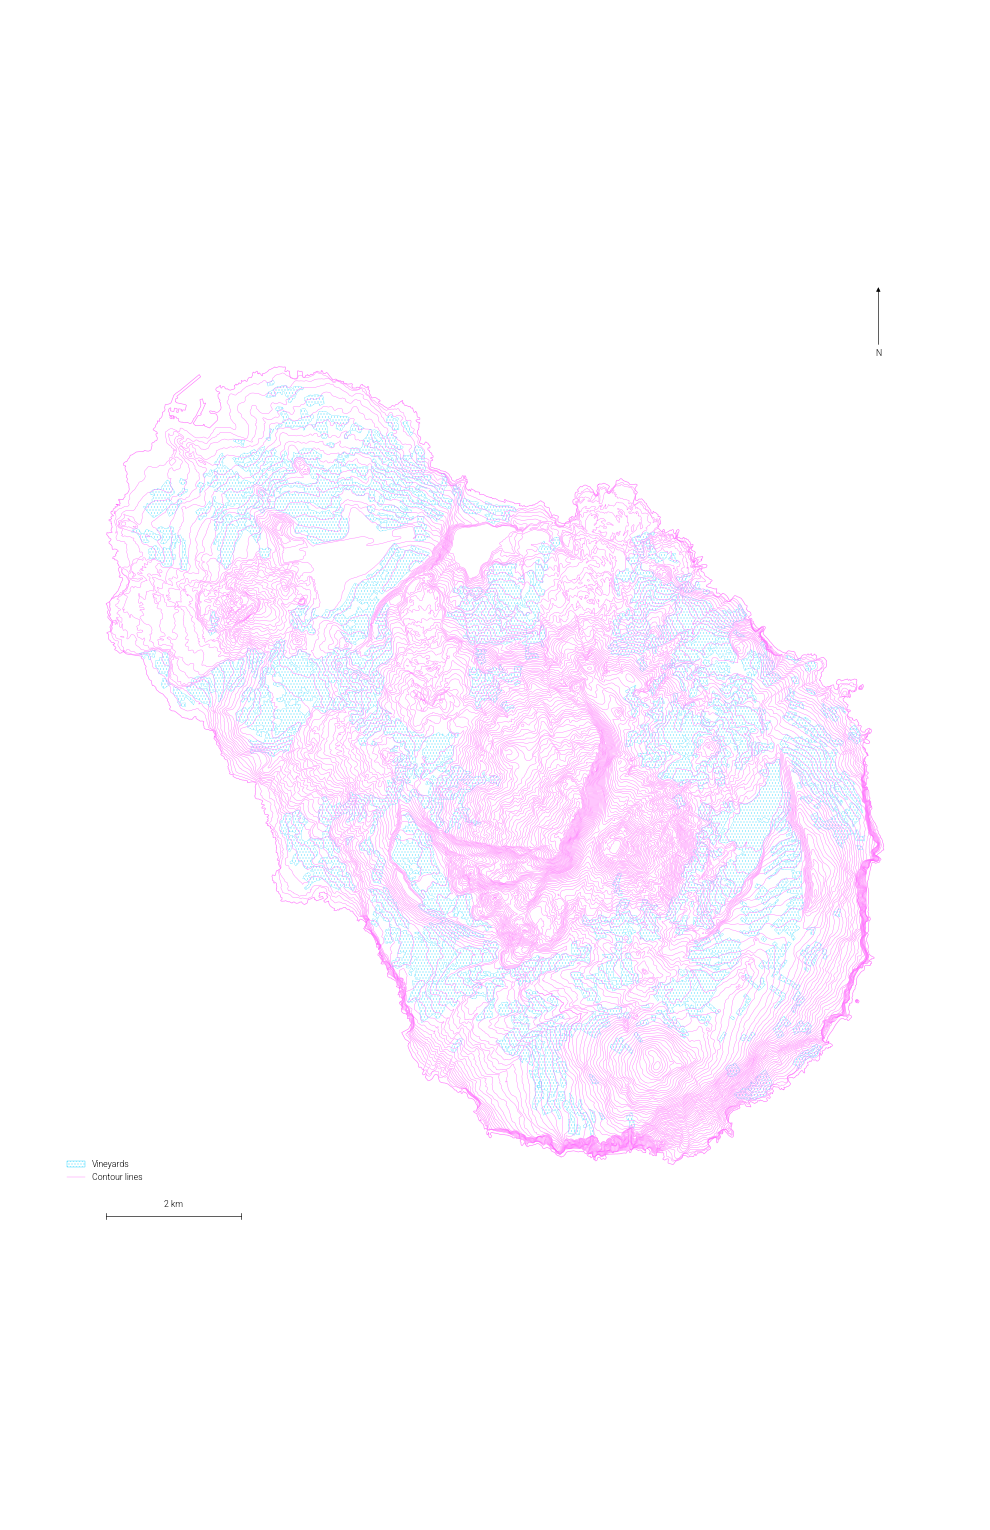

In [30]:
# draw vineyards and topography using the reference map style
fig, ax = plt.subplots(figsize=(11, 17))
fig.subplots_adjust(left=0.06, right=0.94, bottom=0.07, top=0.95)
vineyards.plot(ax=ax, facecolor="none", edgecolor="#00cfff",
              hatch=".....", linewidth=0.15, zorder=2)
draw_relief(ax)
finish_map(ax)
ax.legend(handles=vineyard_legend, loc="lower left", fontsize=7, frameon=False,
          bbox_to_anchor=(0.0, 0.055))
save_map(fig, "Assignement01-Map02-Vineyard.pdf")
plt.show()


In [31]:
# crop the wind raster to Pantelleria before reprojecting it
wind_path = data_folder / "ITA_wind-speed_10m.tif"
with rasterio.open(wind_path) as source:
    wind_mask = pantelleria.to_crs(source.crs)
    wind_crop, crop_transform = mask(source, wind_mask.geometry,
                                     crop=True, filled=True, nodata=np.nan)
    crop_height, crop_width = wind_crop.shape[1:]
    crop_bounds = rasterio.transform.array_bounds(crop_height, crop_width, crop_transform)
    wind_transform, wind_width, wind_height = calculate_default_transform(
        source.crs, land_use.crs, crop_width, crop_height, *crop_bounds)
    wind_values = np.full((wind_height, wind_width), np.nan, dtype="float32")
    # retain the raster's cell-based appearance with nearest-neighbor resampling
    reproject(source=wind_crop[0], destination=wind_values,
              src_transform=crop_transform, src_crs=source.crs,
              src_nodata=np.nan, dst_transform=wind_transform,
              dst_crs=land_use.crs, dst_nodata=np.nan,
              resampling=Resampling.nearest)

# mask the reprojected raster precisely to the island boundary
from rasterio.features import geometry_mask
inside_island = geometry_mask(island_map.geometry, out_shape=wind_values.shape,
                              transform=wind_transform, invert=True)
wind_values = np.ma.masked_where(~inside_island | ~np.isfinite(wind_values), wind_values)
print("Wind speed range (m/s):", float(wind_values.min()), float(wind_values.max()))


Wind speed range (m/s): 0.0422513447701931 9.857965469360352


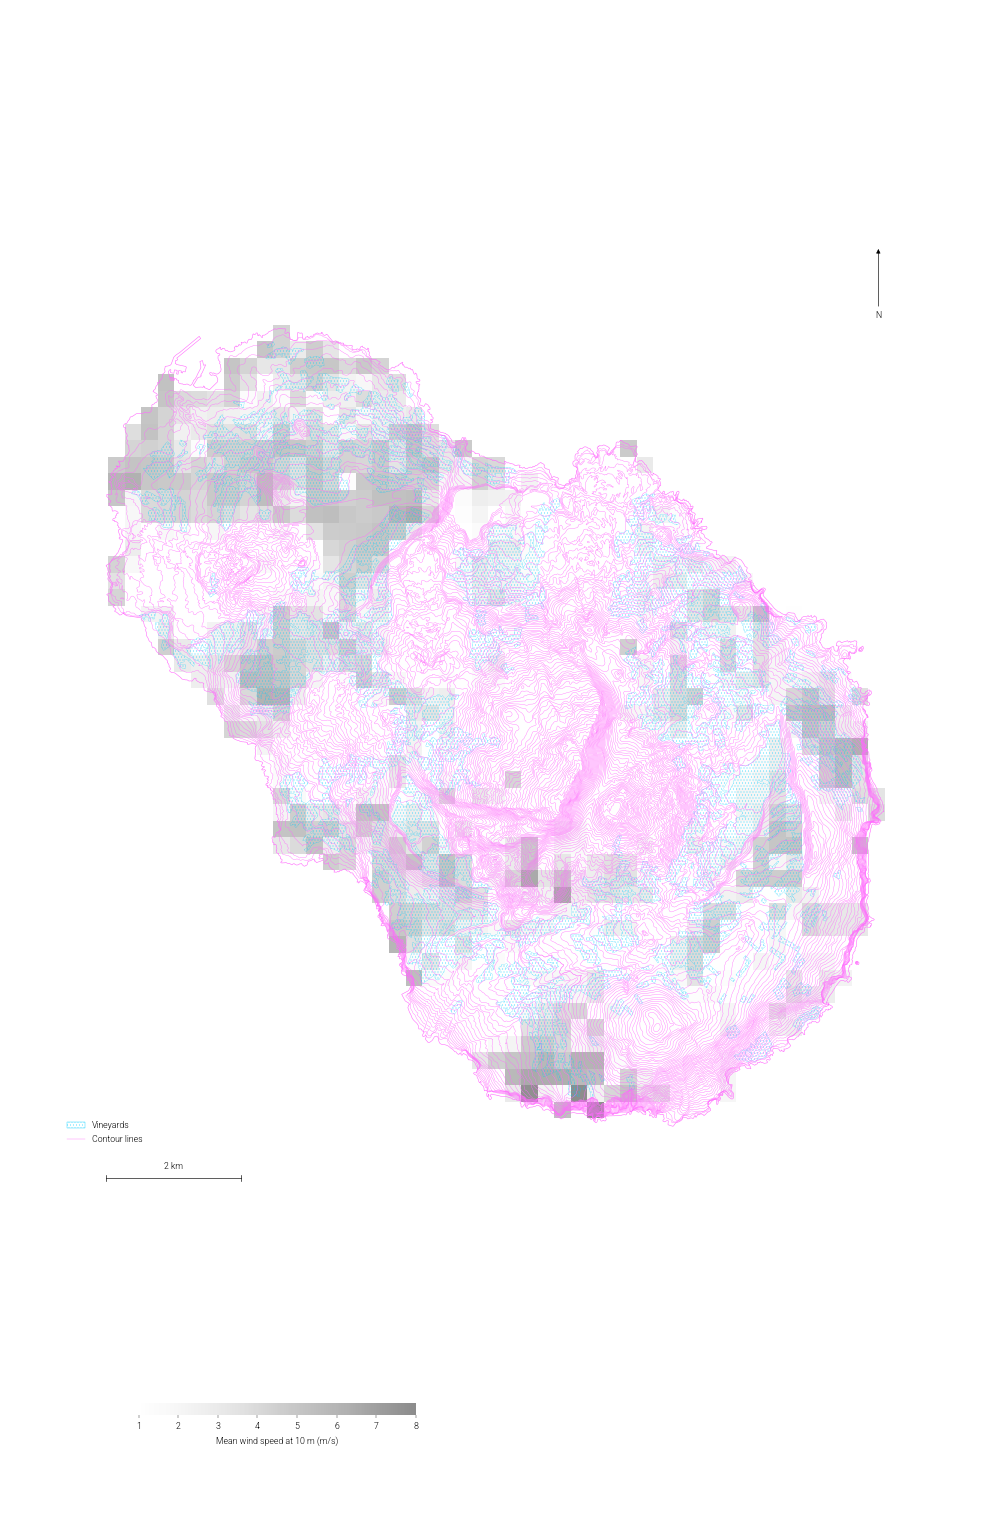

In [32]:
# draw wind speed beneath the vineyards and contour lines
fig, ax = plt.subplots(figsize=(11, 17))
fig.subplots_adjust(left=0.06, right=0.94, bottom=0.12, top=0.95)
wind_image = ax.imshow(wind_values,
                       extent=plotting_extent(wind_values, wind_transform),
                       origin="upper", cmap="Greys", vmin=1, vmax=8,
                       interpolation="nearest", alpha=0.45, zorder=1)
vineyards.plot(ax=ax, facecolor="none", edgecolor="#00cfff",
              hatch=".....", linewidth=0.15, zorder=2)
draw_relief(ax)
finish_map(ax)
ax.legend(handles=vineyard_legend, loc="lower left", fontsize=7, frameon=False,
          bbox_to_anchor=(0.0, 0.055))

# add the grayscale wind legend below the map without changing its aspect
colorbar_ax = fig.add_axes([0.14, 0.075, 0.28, 0.008])
colorbar = fig.colorbar(wind_image, cax=colorbar_ax, orientation="horizontal",
                        ticks=np.arange(1, 9))
colorbar.set_label("Mean wind speed at 10 m (m/s)", fontsize=7)
colorbar.ax.tick_params(labelsize=7, width=0.3, length=2)
colorbar.outline.set_visible(False)
save_map(fig, "Assignement01-Map03-WindSpeed.pdf")
plt.show()
